# 03b · Longitudinal attendance exploration

**Synthetic selected public sample · observation extension.** No states, thresholds, clusters or risk scores. Monthly event-time snapshots do not establish verified capture or point-in-time ingestion availability.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "src").is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data.load import load_tables
from src.features.longitudinal import observation_cutoffs, longitudinal_metrics
tables = load_tables(ROOT)
panel = longitudinal_metrics(tables["members"], tables["checkins"], observation_cutoffs(tables["checkins"]))
print("Synthetic member-snapshot rows:", len(panel))
assert not panel.coverage_verified.any()
display(panel.head())

Synthetic member-snapshot rows: 4197


,member_id,as_of_exclusive,synthetic,coverage_verified,sample_observation_status,membership_tenure_days,first_observed_visit,last_observed_visit,days_since_last_visit,visits_7d,...,preferred_day,preferred_time,branch_diversity,preference_visit_support_90d,export_span_start_as_of,window_inside_export_span_30d,window_inside_export_span_60d,window_inside_export_span_90d,consistency_inside_export_span,snapshot_boundary
0,19,2023-02-01,True,False,visits_present_coverage_unverified,14,2023-01-19 13:06:00,2023-01-30 13:48:00,2.0,3.0,...,Sunday,afternoon_12_17|evening_17_22|morning_05_12,1.0,6.0,2023-01-12,False,False,False,False,calendar_month_end
1,26,2023-02-01,True,False,visits_present_coverage_unverified,22,2023-01-12 18:26:00,2023-01-27 07:44:00,5.0,1.0,...,Friday|Tuesday,evening_17_22,1.0,6.0,2023-01-12,False,False,False,False,calendar_month_end
2,33,2023-02-01,True,False,no_visits_in_public_sample,30,NaT,NaT,NaN,NaN,...,NaN,NaN,NaN,NaN,2023-01-12,False,False,False,False,calendar_month_end
3,35,2023-02-01,True,False,no_visits_in_public_sample,5,NaT,NaT,NaN,NaN,...,NaN,NaN,NaN,NaN,2023-01-12,False,False,False,False,calendar_month_end
4,39,2023-02-01,True,False,no_visits_in_public_sample,17,NaT,NaT,NaN,NaN,...,NaN,NaN,NaN,NaN,2023-01-12,False,False,False,False,calendar_month_end


In [2]:
for name in ["snapshot_summary", "feature_diagnostics", "window_sensitivity", "same_volume_different_history"]:
    print(name)
    display(pd.read_csv(ROOT / f"data/processed/longitudinal/{name}.csv"))

snapshot_summary


,as_of_exclusive,snapshot_boundary,signed_up_roster,members_with_exported_history,no_exported_history,calendar_eligible_30d,calendar_eligible_60d,calendar_eligible_90d,median_visits_30d_calendar_eligible,median_recency_days_represented,positive_30d_count_changes,zero_30d_count_changes,negative_30d_count_changes,median_30d_count_change,eligible_60d_with_zero_previous30,coverage_verified_members
0,2023-02-01,calendar_month_end,44,2,42,0,0,0,NaN,3.5,0,0,0,NaN,0,0
1,2023-03-01,calendar_month_end,60,6,54,2,0,0,9.5,2.0,0,0,0,NaN,0,0
2,2023-04-01,calendar_month_end,69,8,61,7,2,0,6.0,8.5,1,0,1,-0.5,0,0
3,2023-05-01,calendar_month_end,76,8,68,8,7,2,4.5,7.5,2,0,5,-3.0,0,0
4,2023-06-01,calendar_month_end,88,8,80,8,8,7,7.5,3.5,6,1,1,1.5,1,0
5,2023-07-01,calendar_month_end,95,8,87,8,8,8,4.0,5.0,3,1,4,-2.0,1,0
6,2023-08-01,calendar_month_end,103,9,94,8,8,8,7.0,5.0,4,1,3,1.0,1,0
7,2023-09-01,calendar_month_end,107,9,98,9,8,8,6.0,14.0,3,2,3,0.0,1,0
8,2023-10-01,calendar_month_end,123,14,109,9,9,8,4.0,5.0,3,2,4,0.0,2,0
9,2023-11-01,calendar_month_end,136,14,122,14,10,9,7.5,3.0,5,3,2,0.5,3,0


feature_diagnostics


,feature,roster_rows,represented_members,non_null_roster,non_null_represented,null_fraction_roster,distinct_values_represented,zero_fraction_of_nonnull_represented,p25,median,p75,minimum,maximum
0,visits_7d,300,32,32,32,0.893333,2,0.937500,0.000000,0.000000,0.000000,0.0,1.000000
1,visits_30d,300,32,32,32,0.893333,9,0.593750,0.000000,0.000000,2.000000,0.0,11.000000
2,visits_90d,300,32,32,32,0.893333,11,0.500000,0.000000,2.000000,17.500000,0.0,35.000000
3,days_since_last_visit,300,32,32,32,0.893333,30,0.000000,23.750000,85.500000,264.250000,1.0,652.000000
4,attendance_frequency_30d,300,32,32,32,0.893333,9,0.593750,0.000000,0.000000,0.466667,0.0,2.566667
5,attendance_frequency_90d,300,32,29,29,0.903333,10,0.551724,0.000000,0.000000,1.322222,0.0,2.722222
6,attendance_change_30_vs_previous30,300,32,31,31,0.896667,9,0.645161,-3.000000,0.000000,0.000000,-11.0,3.000000
7,attendance_pct_change_30_vs_previous30,300,32,13,13,0.956667,11,0.153846,-0.888889,-0.714286,0.000000,-1.0,0.428571
8,attendance_change_30_vs_90_baseline,300,32,29,29,0.903333,12,0.551724,-3.500000,0.000000,0.000000,-11.0,5.500000
9,active_weeks_8w,300,32,31,31,0.896667,7,0.548387,0.000000,0.000000,5.000000,0.0,8.000000


window_sensitivity


,member_id,as_of_exclusive,synthetic,coverage_verified,visits_30d,visits_previous30d,visits_90d,attendance_change_30_vs_previous30,attendance_change_30_vs_90_baseline,attendance_frequency_30d,attendance_frequency_90d,baseline_change_sign_agrees,frequency_30d_minus_90d
0,1,2024-12-29,True,False,1.0,12.0,20.0,-11.0,-8.5,0.233333,1.555556,True,-1.322222
1,2,2024-12-29,True,False,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,True,0.000000
2,3,2024-12-29,True,False,6.0,6.0,14.0,0.0,2.0,1.400000,1.088889,False,0.311111
3,4,2024-12-29,True,False,0.0,0.0,7.0,0.0,-3.5,0.000000,0.544444,False,-0.544444
4,5,2024-12-29,True,False,1.0,12.0,25.0,-11.0,-11.0,0.233333,1.944444,True,-1.711111
5,6,2024-12-29,True,False,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,True,0.000000
6,7,2024-12-29,True,False,0.0,9.0,17.0,-9.0,-8.5,0.000000,1.322222,True,-1.322222
7,8,2024-12-29,True,False,10.0,7.0,19.0,3.0,5.5,2.333333,1.477778,True,0.855556
8,9,2024-12-29,True,False,11.0,14.0,35.0,-3.0,-1.0,2.566667,2.722222,True,-0.155556
9,10,2024-12-29,True,False,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,True,0.000000


same_volume_different_history


,member_id,visits_30d,visits_previous30d,attendance_change_30_vs_previous30
0,1,1.0,12.0,-11.0
1,15,1.0,9.0,-8.0


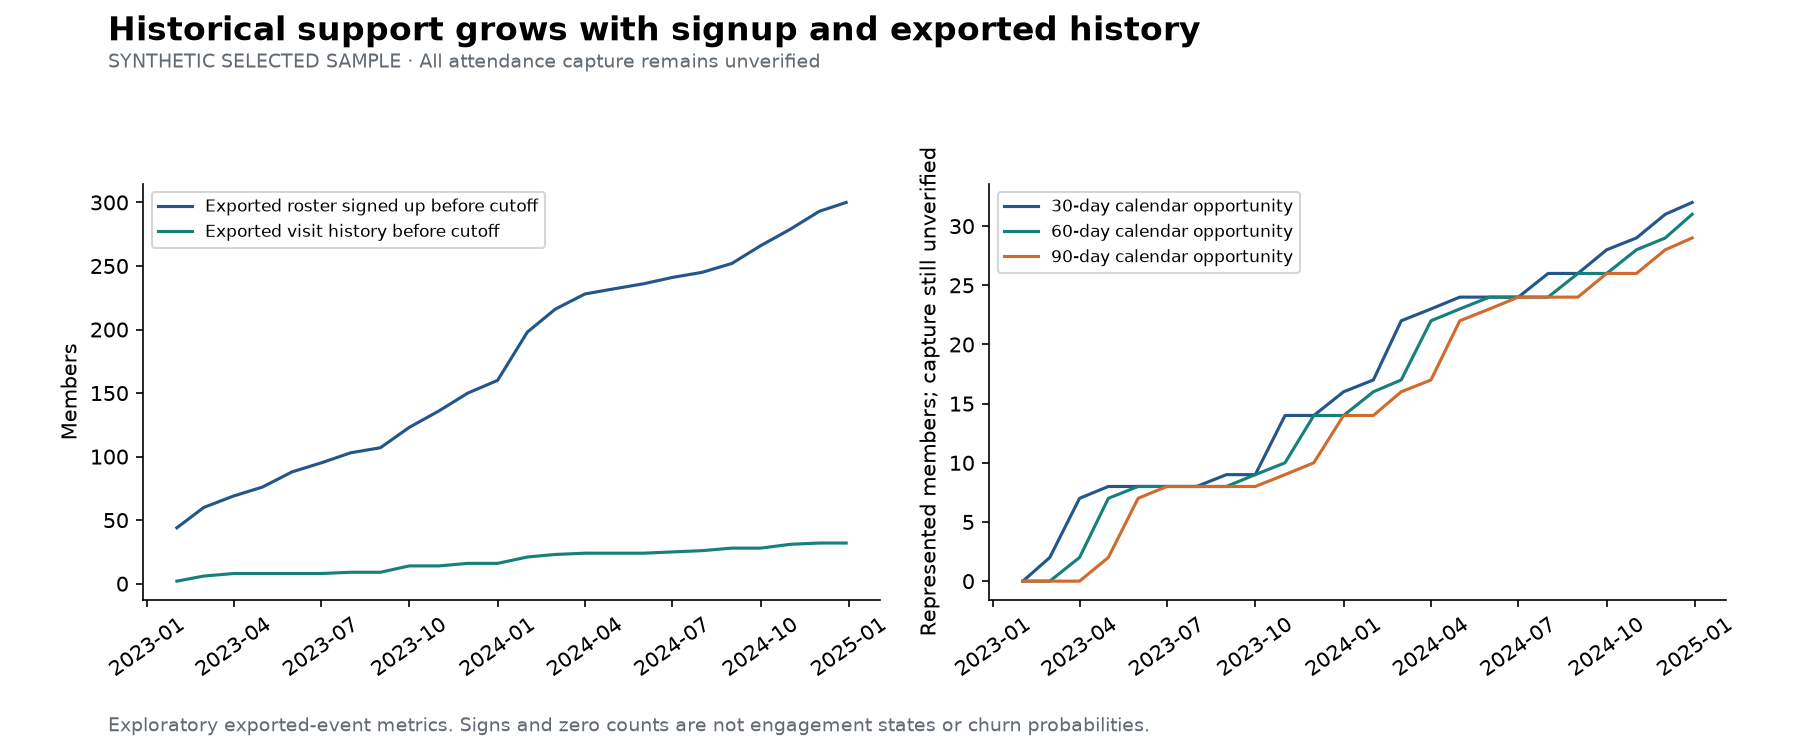

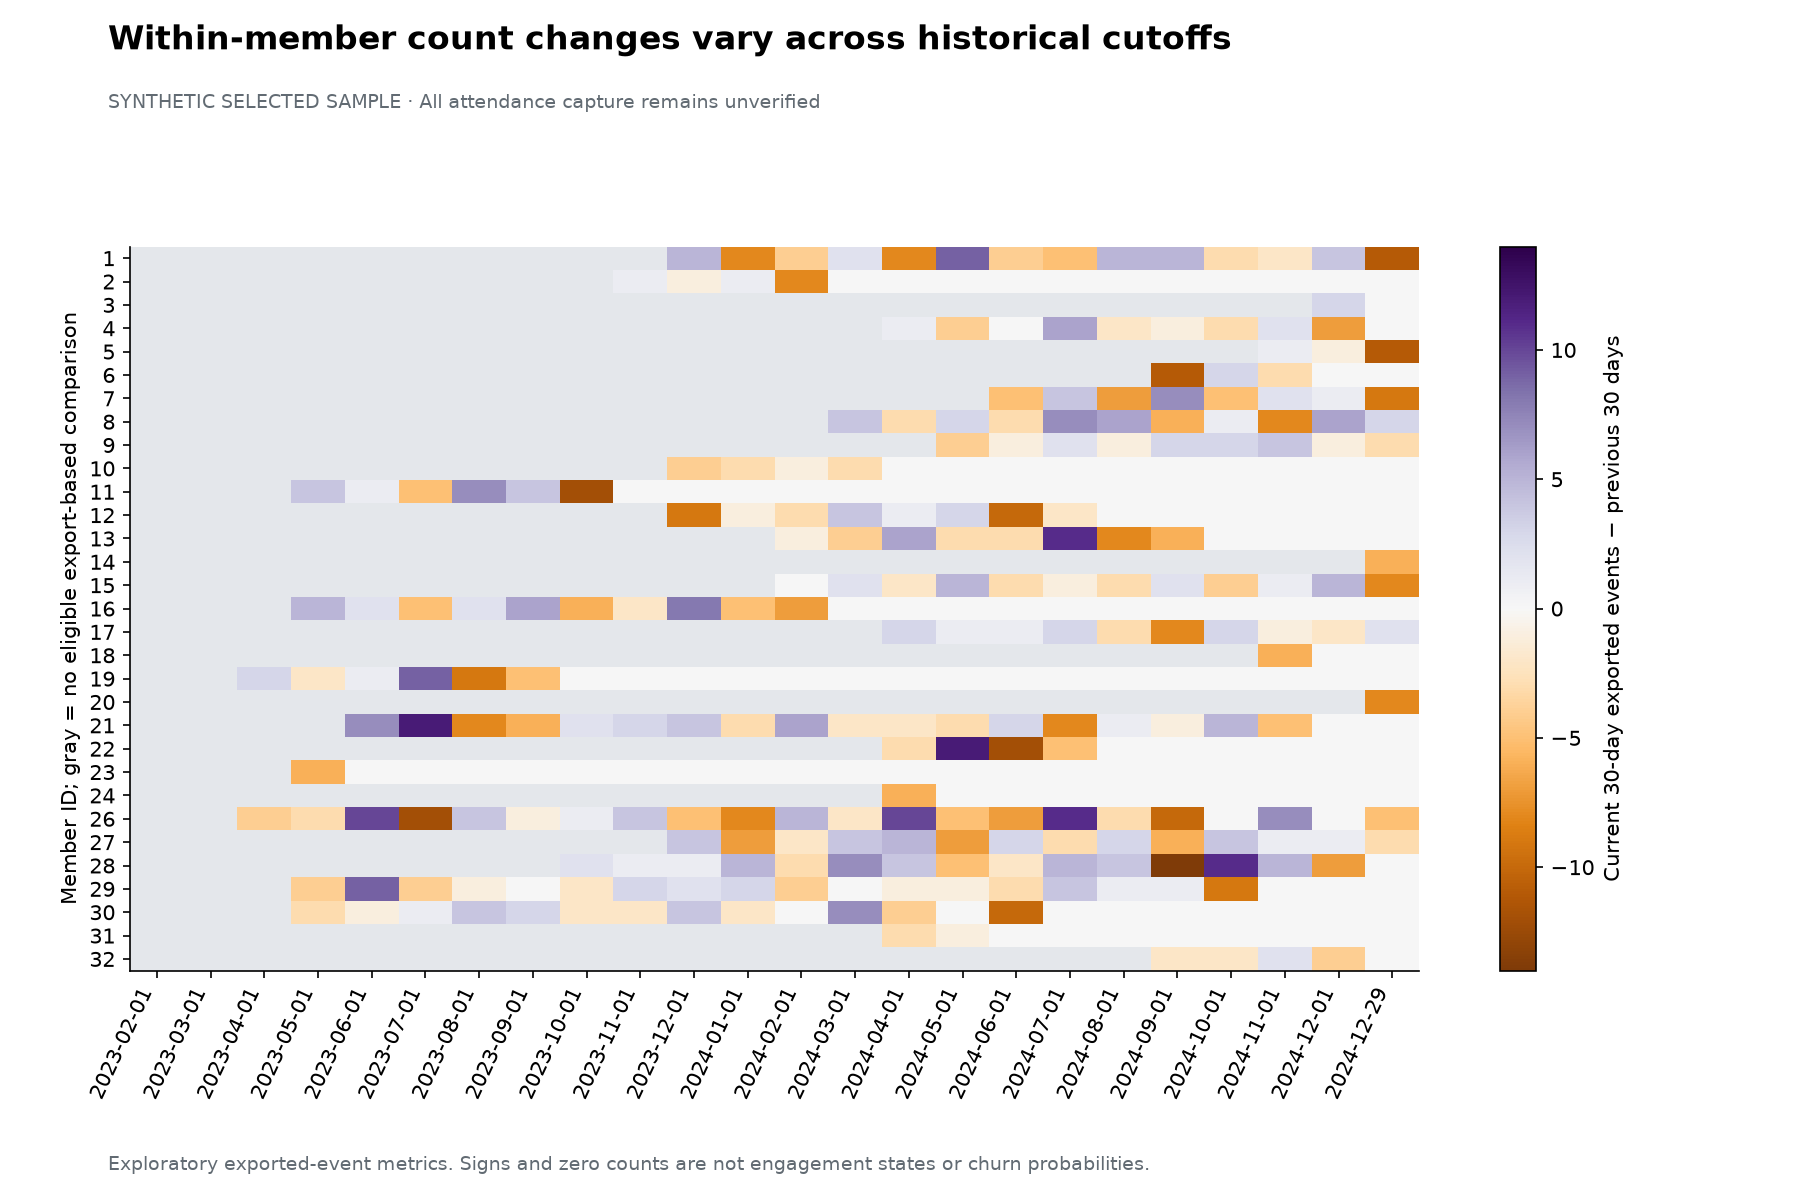

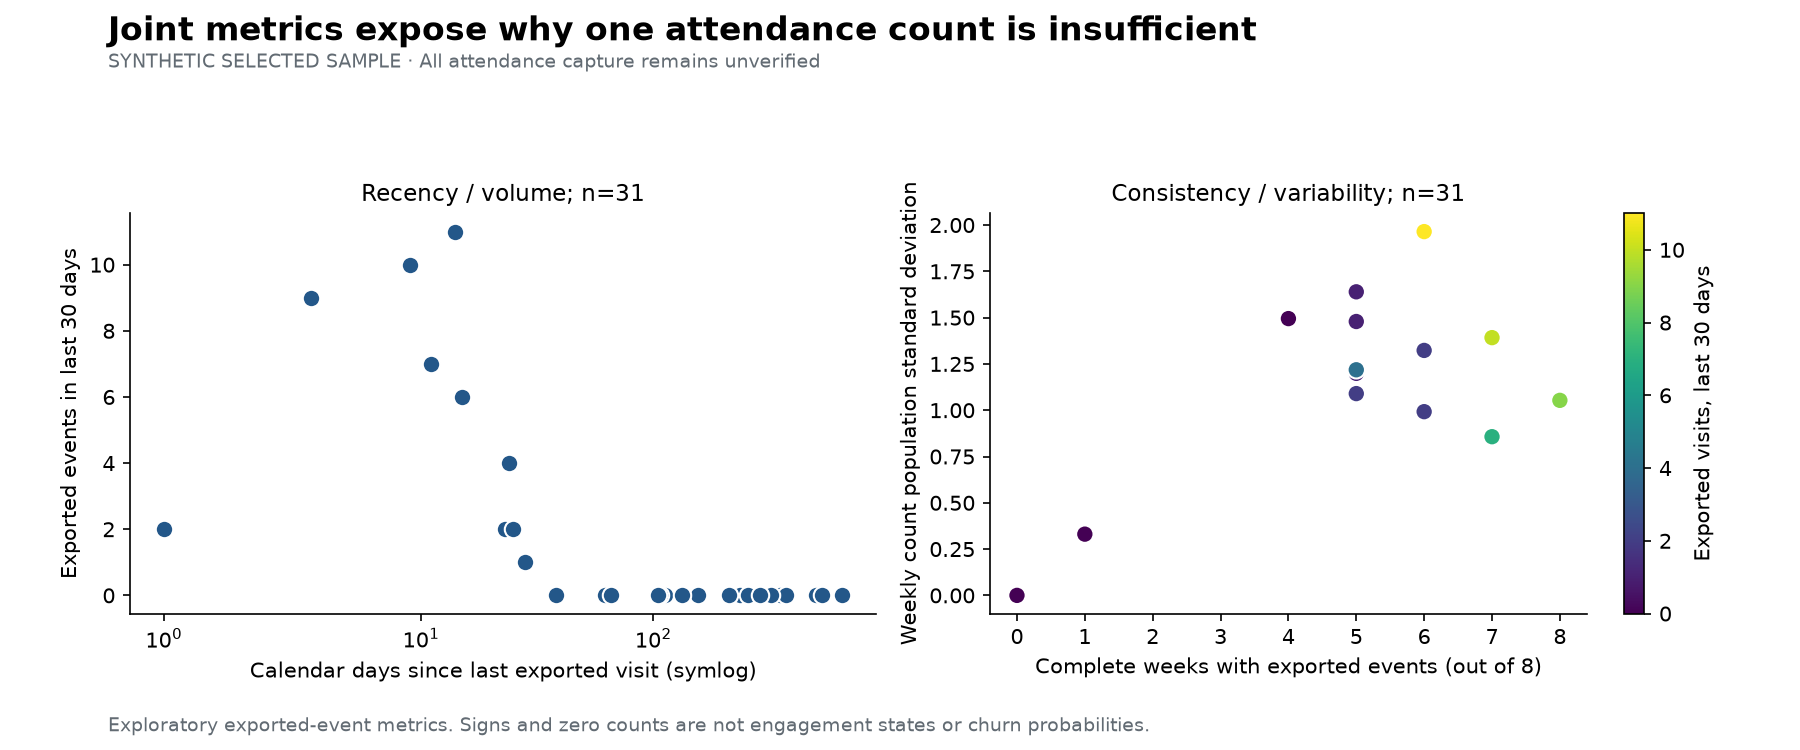

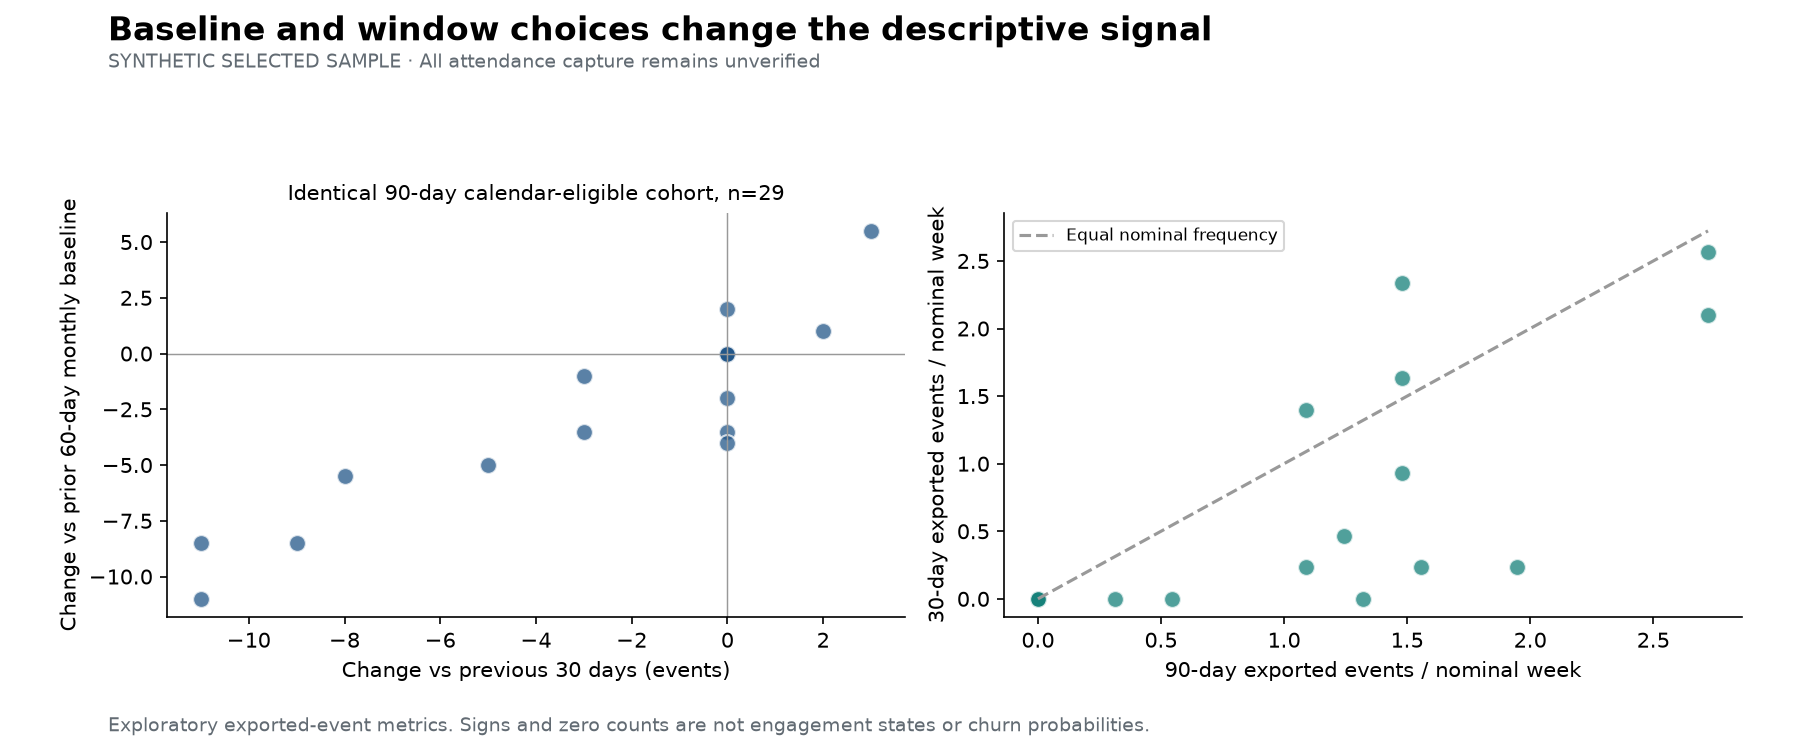

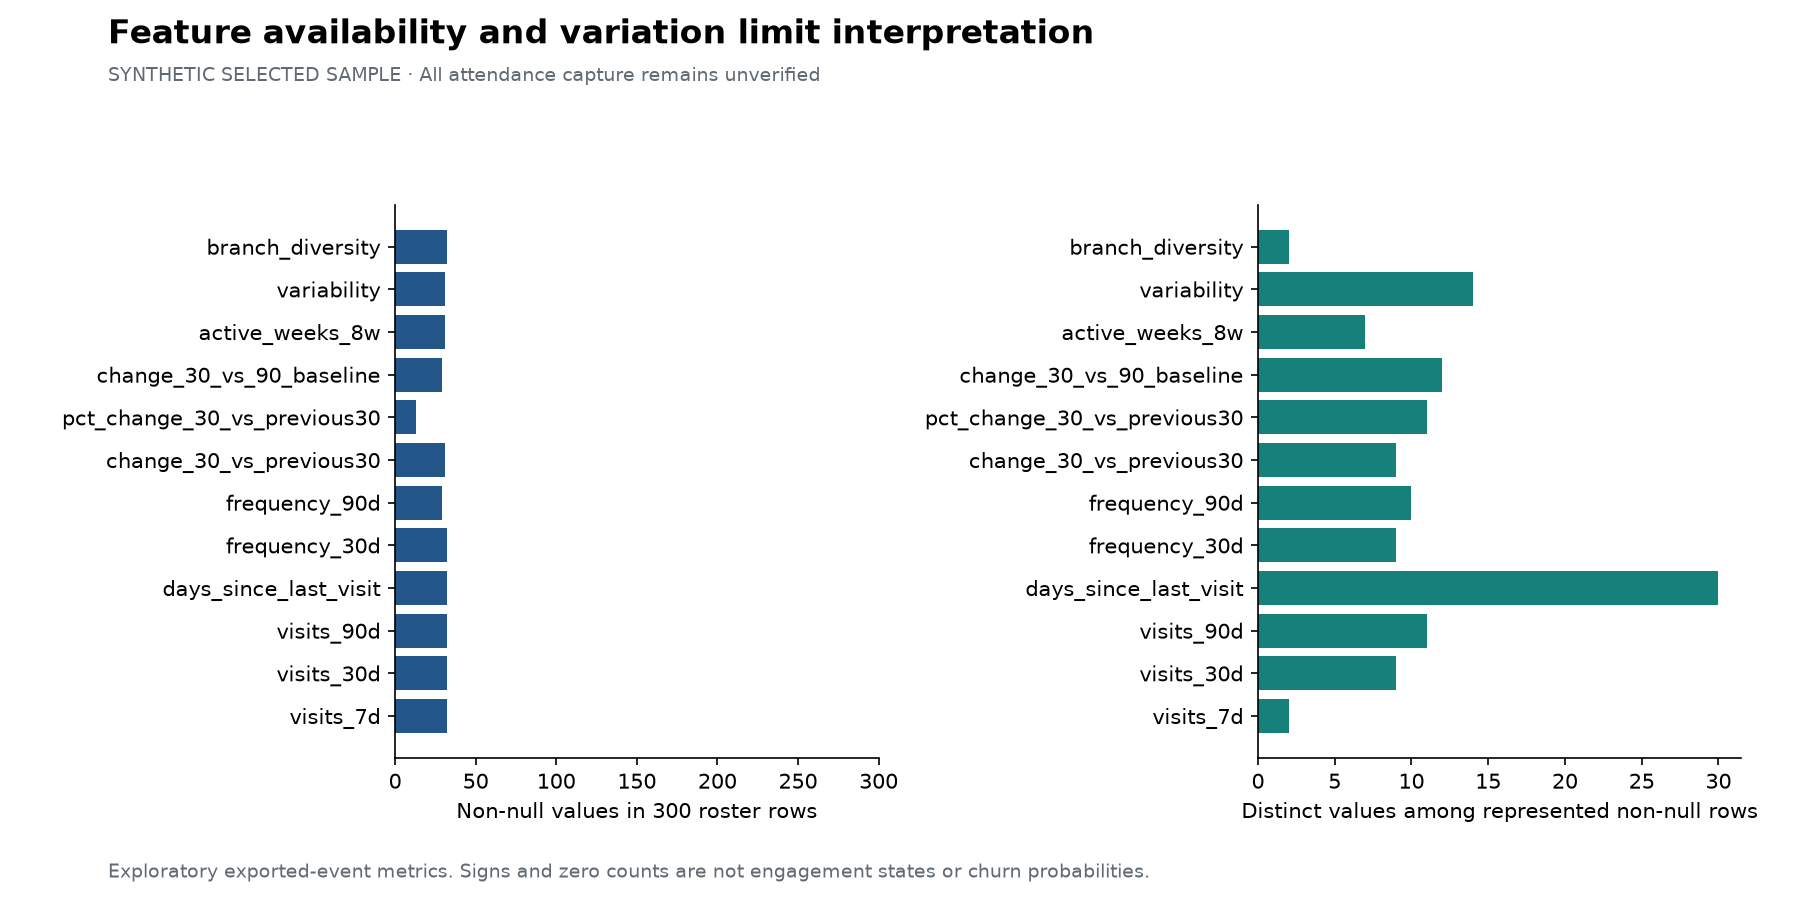

In [3]:
for path in sorted((ROOT / "reports/longitudinal/figures").glob("*.png")):
    display(Image(filename=str(path)))

## Interpretation and next gate

Current attendance volume alone loses within-member history. Baseline choices can change a count-change sign; this is not a validated state. Unknown coverage remains unknown in every snapshot. Retrospective roster availability and overlapping windows prevent prospective or independent-validation claims. Obtain member capture intervals, source timezone and access/closure calendars before calibrating states. See docs/longitudinal_methodology.md and reports/longitudinal/readiness.json.